# Student Performance Analysis and Prediction

## 1. Project Overview

In this project I analyse a student performance dataset from Kaggle. It has **395 students** and **33 columns** such as study time, past failures, absences, family background and three grades (G1, G2 and G3). G3 is the final grade.

**What I want to do in this project:**
- Explore the data and find out which factors seem related to a student's final grade (G3)
- Build a **Linear Regression** model to predict the final grade as a number
- Convert the grade into three levels (Low, Medium, High) and try **Logistic Regression** and **KNN** to predict the level

**Tools used:** pandas, matplotlib, seaborn, scikit-learn

## 2. Importing Libraries

These are the main libraries for data handling and plotting. The scikit-learn imports are added later, in the cells where they are first used.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Loading the Dataset

I load the CSV file into a pandas DataFrame called `df` and look at the first 5 rows. Each row is one student.

In [1]:
df = pd.read_csv("/kaggle/input/datasets/devansodariya/student-performance-data/student_data.csv")

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 4. Understanding the Dataset

### 4.1 Size, data types and summary statistics

Here I check how many rows and columns there are, the data type of each column, and basic statistics (mean, min, max, etc.) of the numerical columns.

In [2]:
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


**What I noticed:**
- The dataset has 395 rows and 33 columns (shown at the top of `df.info()`).
- 16 columns are numerical (`int64`) and 17 are text/categorical (`object`).
- The final grade G3 has a mean of about 10.4 and goes from 0 to 20.
- `absences` has a median of 4 but a maximum of 75, so a few students have a very high number of absences.

### 4.2 Column names

In [3]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

## 5. Data Cleaning

Before analysing the data I check for missing values, duplicate rows and wrong data types.

In [4]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

**Result of the checks:**
- There are no missing values (every column has a count of 0).
- There are no duplicate rows (the count is 0).
- Numbers are stored as `int64` and text columns as `object`, so the data types are fine.

The data was already clean, so I did not remove or change any rows. The large `absences` values were also kept as they are.

## 6. Exploratory Data Analysis (EDA)

In this section I explore the data using graphs. The final grade (G3) is the main column I focus on.

### 6.1 Distribution of Final Grades

**Question:** What does the distribution of students' final grades (G3) look like?

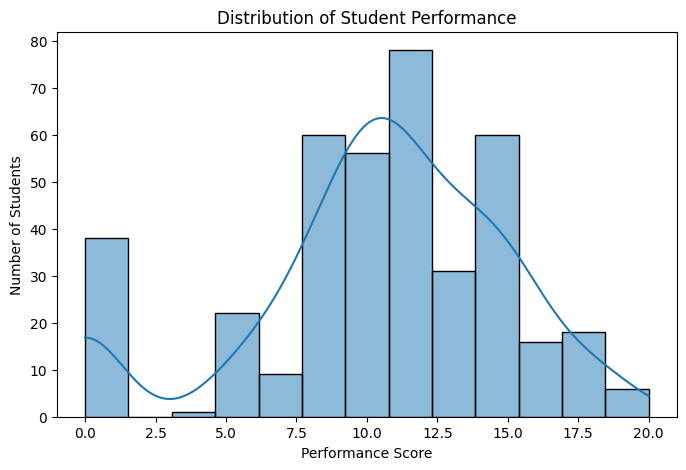

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="G3", kde=True)

plt.title("Distribution of Student Performance")
plt.xlabel("Performance Score")
plt.ylabel("Number of Students")

plt.show()

**Explanation:** Most students have a final grade between about 8 and 15, and the highest bar is around 10 to 12. There is also a separate group of students near 0, which makes the left side of the graph longer. Very few students score above 17. This also explains why the mean (about 10.4) is a bit lower than the median (11).

### 6.2 Study Time vs Final Grade

**Question:** Does study time have a relationship with students' final grades?

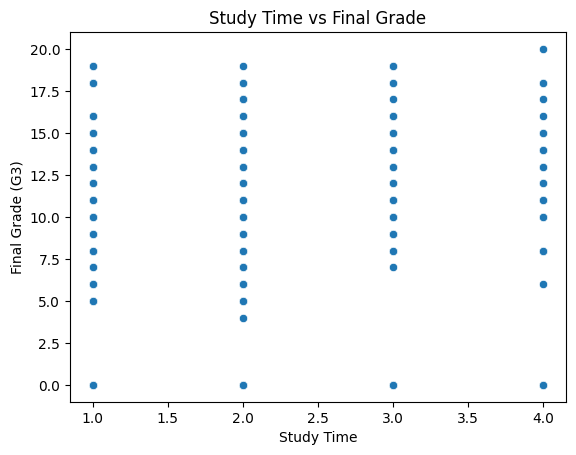

In [6]:
#Does studying more relate to better performance?

# Scatter plot
sns.scatterplot(data=df, x="studytime", y="G3")

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time")
plt.ylabel("Final Grade (G3)")
plt.show()

**Explanation:** Study time only has four values (1 to 4), so the points form four vertical lines. At every study time level there are students with low grades and students with high grades, and even students with 0. So there is no clear upward trend in this graph. More study time does not guarantee a better grade here, and other factors probably matter too. The correlation heatmap below shows the same thing with a number.

### 6.3 Performance by Gender

**Question:** Do male and female students have different average final grades?

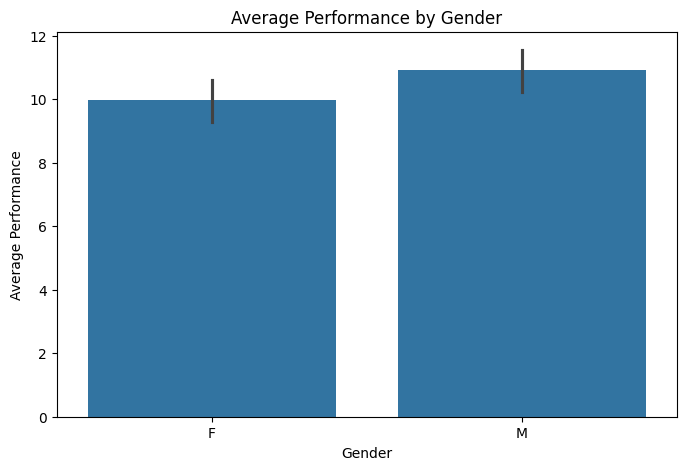

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="sex",
    y="G3"
)

plt.title("Average Performance by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Performance")

plt.show()

**Explanation:** Each bar shows the average G3 for that group, and the black line is the uncertainty range around the average. Male students (M) have a slightly higher average (a little under 11) than female students (F) (about 10). The black lines of the two bars overlap a little, so the difference is small and I would not say that one gender performs clearly better than the other.

### 6.4 Correlation Between Numerical Features

**Question:** Which numerical features are most strongly related to the final grade (G3), and to each other?

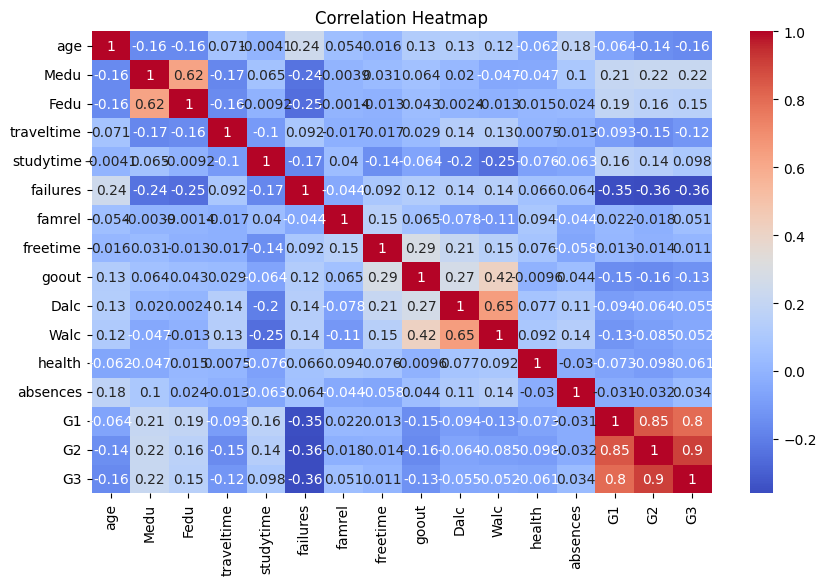

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 6))

sns.heatmap(corr, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

**Explanation:** Correlation goes from -1 to +1. Values close to +1 mean both columns increase together, values close to -1 mean one goes up when the other goes down, and values close to 0 mean almost no linear relationship.

- **G1, G2 and G3** are very strongly related (G2 and G3 is 0.9, G1 and G3 is 0.8), which means a student's earlier grades are close to their final grade.
- **failures** has the strongest negative relationship with G3 (about -0.36) among the other columns, so students with more past failures tend to have lower grades.
- **studytime** has a weak positive relationship with G3 (about 0.10), and **absences** is almost 0 (about 0.03).
- Some features are related to each other, for example `Medu` and `Fedu` (0.62) and `Dalc` and `Walc` (0.65).

Correlation only shows that two columns move together, not that one causes the other.

## 7. Feature Selection

For the machine learning part I use three numerical features that describe a student's study habits and past record:

- `studytime`: weekly study time
- `absences`: number of school absences
- `failures`: number of past class failures

The target I want to predict is **G3** (final grade). G1 and G2 are not used as features here, even though the heatmap shows they are strongly correlated with G3.

## 8. Machine Learning

I use two approaches on the same three features:

- **Part A:** Linear Regression, which predicts the final grade G3 as a number.
- **Part B:** Classification, where G3 is converted into Low / Medium / High and predicted using Logistic Regression and KNN.

Each part follows the same steps: features and target, train-test split, model training, predictions and evaluation.

---
## Part A: Predicting the Final Grade (Linear Regression)

### 8.1 Features (X) and Target (y)

`X` contains the input columns the model learns from, and `y` is the value we want to predict.

In [9]:
X=df[["studytime","absences","failures"]]
y=df["G3"]

### 8.2 Train-Test Split

The data is divided into 80% for training and 20% for testing. The model learns only from the training data, and the test data is kept hidden so I can check how well the model works on new students. `random_state=42` makes the split the same every time I run the code.

In [10]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

### 8.3 Model Training

Linear Regression finds the best straight-line relationship between the input features and G3 using the training data.

In [11]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

### 8.4 Predictions

The trained model predicts G3 for the students in the test set. Here are the first 10 predictions.

In [12]:
y_pred=model.predict(X_test)
print(y_pred[:10])

[ 3.58392694 10.42923826  8.8808786  11.14888443  6.73675426 10.81853377
 10.90112144 11.56182275 10.81853377 10.90112144]


### 8.5 Model Evaluation

I use three common regression metrics to compare the predictions with the real grades:

- **MAE (Mean Absolute Error):** the average difference between predicted and actual grades, in marks.
- **MSE (Mean Squared Error):** the average of the squared errors, so large mistakes are punished more.
- **R² Score:** how much of the variation in G3 the model explains. 1 is perfect and 0 means it is no better than always predicting the average.

In [13]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

print("MAE:",mae)
print("MSE:",mse)
print("R2 Score:",r2)

MAE: 3.5605831369551644
MSE: 19.8746907446437
R2 Score: 0.03074152988683987


**Explanation:** The MAE is about 3.56, so on a 0 to 20 scale the predictions are off by around 3.5 marks on average. The R² score is only about 0.03, which means the model explains roughly 3% of the variation in final grades. This is very low, so these three features alone are not enough to predict G3 well.

### 8.6 Actual vs Predicted Values

To see the errors more clearly, I put the actual and predicted grades side by side and then plot them.

In [14]:
comparison = pd.DataFrame({
    "Actual_G3": y_test.values,
    "Predicted_G3": y_pred
})

print(comparison.head(10))

   Actual_G3  Predicted_G3
0         10      3.583927
1         12     10.429238
2          5      8.880879
3         10     11.148884
4          9      6.736754
5         13     10.818534
6         18     10.901121
7          6     11.561823
8          0     10.818534
9         14     10.901121


In [15]:
import matplotlib.pyplot as plt 

plt.scatter(y_test,y_pred)

plt.xlabel("Actual G3")
plt.ylabel("Predicted G3")
plt.title("Actual vs Predicted Student Grades")

plt.show()

**Explanation:** If the model was perfect, all the points would lie on a diagonal line (predicted = actual). Here the predictions stay mostly between about 10 and 12 for almost every actual grade. For example, in the table above a student with an actual grade of 0 got a prediction of about 10.8 and a student with 18 got about 10.9. So the model mostly predicts values close to the average and cannot separate the weak students from the strong ones. This matches the very low R² score.

---
## Part B: Predicting the Performance Level (Classification)

### 8.7 Creating Performance Categories

I create a new column `performance_category` from G3 using this rule:

- **High:** G3 is 16 or more
- **Medium:** G3 is from 10 to 15
- **Low:** G3 is below 10

In [16]:
def categorize_score(score):
    if score >= 16:
        return "High"
    elif score >= 10:
        return "Medium"
    else:
        return "Low"

df["performance_category"] = df["G3"].apply(categorize_score)

In [17]:
print(df[["G3", "performance_category"]].head())

   G3 performance_category
0   6                  Low
1   6                  Low
2  10               Medium
3  15               Medium
4  10               Medium


### 8.8 Features (X) and Target (y)

The features are the same three columns. The target is now the category column, so this is a classification problem.

In [18]:
X = df[["studytime", "absences", "failures"]]

y = df["performance_category"]

### 8.9 Train-Test Split

Same 80/20 split as before. I also use `stratify=y`, which keeps the proportion of Low, Medium and High students similar in both the training and test sets.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### 8.10 Model Training: Logistic Regression

Logistic Regression is used for classification. It calculates the probability of each class and picks the most likely one. `max_iter=1000` gives the model enough steps to finish learning.

In [20]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

### 8.11 Predictions

The first 10 predicted categories for the test students:

In [21]:
y_pred = model.predict(X_test)

print(y_pred[:10])

['Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Medium' 'Low' 'Low'
 'Medium' 'Medium']


### 8.12 Model Evaluation: Accuracy

Accuracy is the fraction of test students whose category was predicted correctly.

In [22]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.5443037974683544


**Explanation:** The accuracy is about 54.4%, so a little more than half of the test students were classified correctly. In the first 10 predictions above, the model mostly predicted "Medium" and none were "High". Accuracy alone does not show which classes the model gets wrong.

### 8.13 Trying Another Model: KNN

To compare with Logistic Regression I also train a K-Nearest Neighbors (KNN) classifier. For each student it looks at the 5 most similar students in the training data (`n_neighbors=5`) and predicts the most common category among them.

In [23]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))

KNN Accuracy: 0.5063291139240507


**Explanation:** KNN gets about 50.6% accuracy, slightly lower than Logistic Regression (54.4%). The test set has about 79 students, so this difference is only around 3 students. Both models perform similarly, and neither is very strong with these three features.

## 9. Results

These are the results from the outputs above.

| Model | Task | Metric | Value |
|---|---|---|---|
| Linear Regression | Predict G3 (number) | MAE | 3.56 |
| Linear Regression | Predict G3 (number) | MSE | 19.87 |
| Linear Regression | Predict G3 (number) | R² Score | 0.031 |
| Logistic Regression | Predict Low / Medium / High | Accuracy | 0.544 (54.4%) |
| KNN (k = 5) | Predict Low / Medium / High | Accuracy | 0.506 (50.6%) |

**Main findings:**
- Most students scored between about 8 and 15 in the final grade, with a separate group near 0.
- Study time had only a weak relationship with G3, and `failures` had the strongest negative relationship among the features used.
- Linear Regression explained only about 3% of the variation in G3.
- Logistic Regression was slightly better than KNN for predicting the performance category.

## 10. Conclusion

In this project I analysed the performance of 395 students and looked at which factors are related to the final grade (G3). The EDA showed that most students scored between 8 and 15, that study time has only a weak relationship with the final grade, and that past failures had the strongest negative relationship among the features I used. I used Linear Regression to predict G3 from study time, absences and failures, but it gave a very low R² score of about 0.03 and an MAE of about 3.6 marks, so it is not a good predictor. I also divided students into Low, Medium and High levels, and Logistic Regression (about 54% accuracy) did slightly better than KNN (about 51%). From this project I learned the full workflow of a small data science project: checking and cleaning data, doing EDA, choosing features, training models and evaluating them. I also learned that a model can only be as good as the features it gets. The main limitation is that I used only three features on a small dataset, so in future I can add more features, check how many students are in each category, and try other models to improve the results.